In [1]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


Initial guess [-17, 12], Result: [0.99999546 0.99999091], Value: 2.061405125335558e-11, Success: True, Iterations: 129, Time: 0.0244 sec
Initial guess [3, 7], Result: [0.99999564 0.99999127], Value: 1.9028451089739715e-11, Success: True, Iterations: 32, Time: 0.0058 sec
Initial guess [5, 5], Result: [0.99999742 0.99999483], Value: 6.670628346219875e-12, Success: True, Iterations: 54, Time: 0.0083 sec
Initial guess [0, 0], Result: [0.99999467 0.99998932], Value: 2.8439990629105454e-11, Success: True, Iterations: 19, Time: 0.0026 sec
Initial guess [-4, 4], Result: [0.99999558 0.99999114], Value: 1.956595001611041e-11, Success: True, Iterations: 62, Time: 0.0086 sec
Initial guess [4, 0], Result: [0.99999556 0.99999112], Value: 1.9708748423576696e-11, Success: True, Iterations: 67, Time: 0.0097 sec


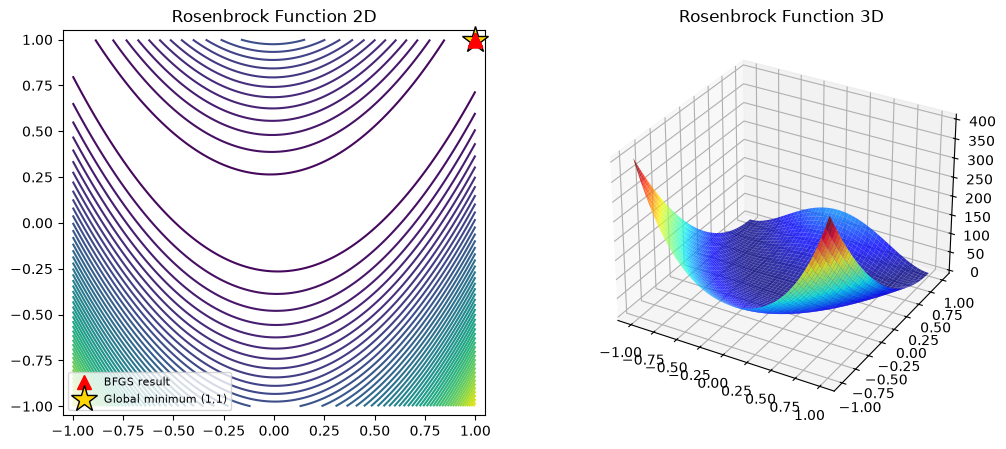

PyGAD initial guess [-17, 12], Solution: [0.93218488 0.86785007], Value: 0.004724014790892835, iterations: 2000, Time: 0.5937 sec


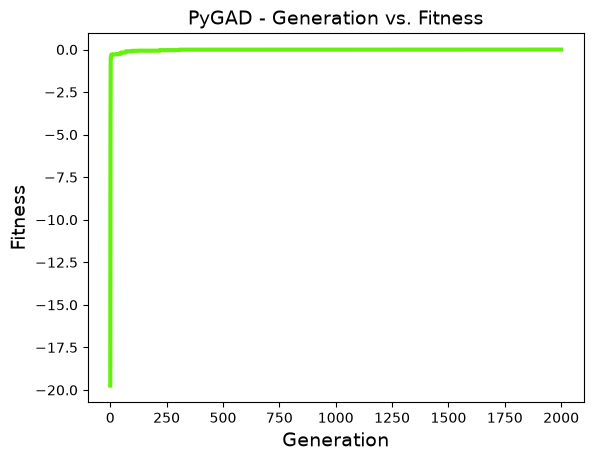

PyGAD initial guess [3, 7], Solution: [0.98332147 0.96711035], Value: 0.00028175426627188415, iterations: 2000, Time: 0.5928 sec


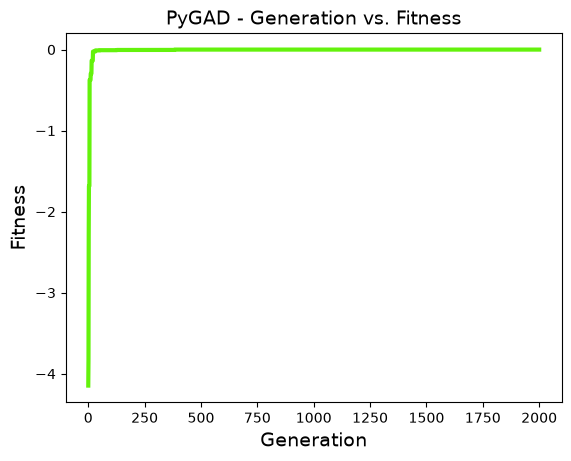

PyGAD initial guess [5, 5], Solution: [1.00510981 1.01082211], Value: 5.9331679377572094e-05, iterations: 2000, Time: 0.5533 sec


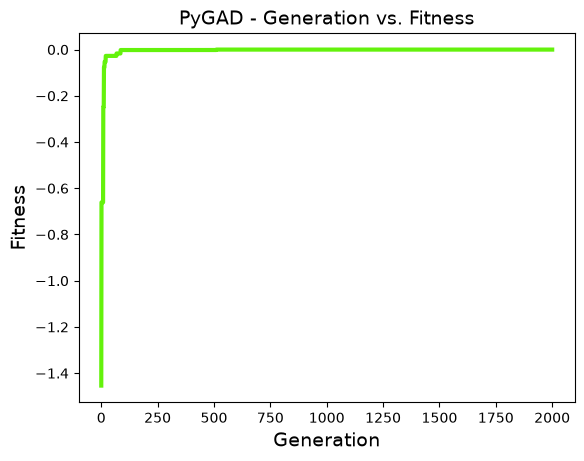

PyGAD initial guess [0, 0], Solution: [0.99876934 0.99825836], Value: 5.309197392078922e-05, iterations: 2000, Time: 0.5645 sec


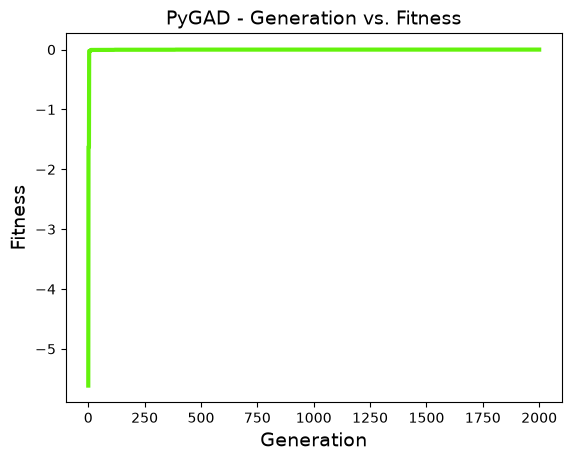

PyGAD initial guess [-4, 4], Solution: [0.99445029 0.98884669], Value: 3.1516368549044786e-05, iterations: 2000, Time: 0.6151 sec


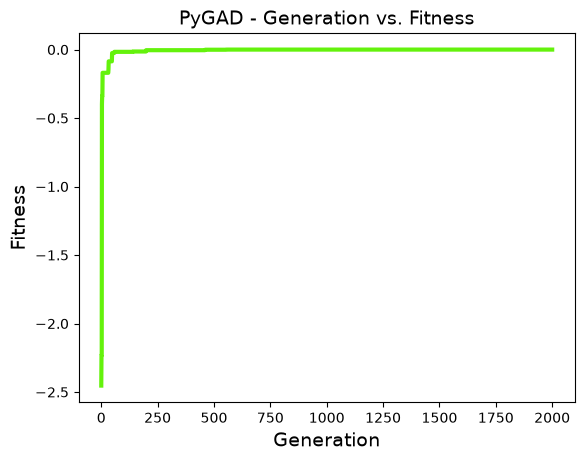

PyGAD initial guess [4, 0], Solution: [1.00189468 1.00378119], Value: 3.6036667694182267e-06, iterations: 2000, Time: 0.5706 sec


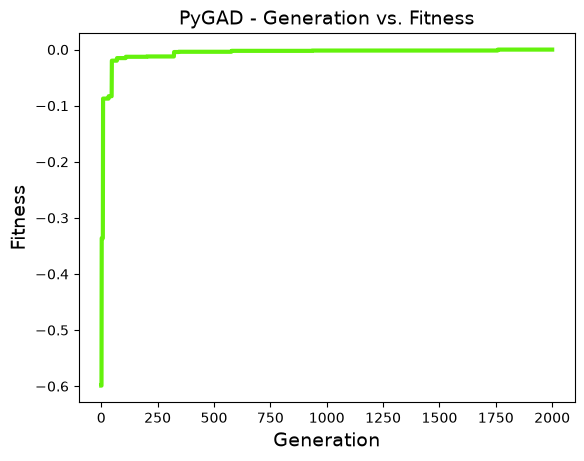

In [12]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# ---------------- Run Scipy Optimization FIRST ----------------
scipy_results = []  # (guess, final_point) pairs
init_guesses = [[-17, 12], [3, 7], [5, 5], [0, 0], [-4, 4], [4, 0]]

for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, "
          f"Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")
    scipy_results.append((guess, result.x))

# ---------------- 2D & 3D plots (same as original) ----------------
x_range = np.linspace(-1, 1, 2500)
y_range = np.linspace(-1, 1, 2500)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")

# overlay results and global minimum directly on ax1
for i, (guess, final) in enumerate(scipy_results):
    ax1.plot(final[0], final[1], '^', color='red', markersize=10, zorder=5,
              clip_on=False, label='BFGS result' if i == 0 else "")
ax1.plot(1, 1, '*', color='gold', markersize=20, markeredgecolor='black',
          zorder=4, clip_on=False, label='Global minimum (1,1)')

# move legend away from the corner where the markers are
ax1.legend(fontsize=8, loc='lower left')

ax1.set_xlim(-1.05, 1.05)
ax1.set_ylim(-1.05, 1.05)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")

plt.show()

# ---------------- PyGAD Optimization ----------------
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution)  # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low': -2, 'high': 2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {rosenbrock(solution)}, "
          f"iterations: {iters}, Time: {elapsed_time:.4f} sec")
    ga_instance.plot_fitness()

we are not getting exact solution so need to explain that and also how much accuracy its taking. Take different initial guess and run.
Edit the plot part to show exact solution and the solution i am getting and also show global mun and initial guess legend
Plot all fitness and generation part together for comparison. Include result from intitial guess in contour plots.

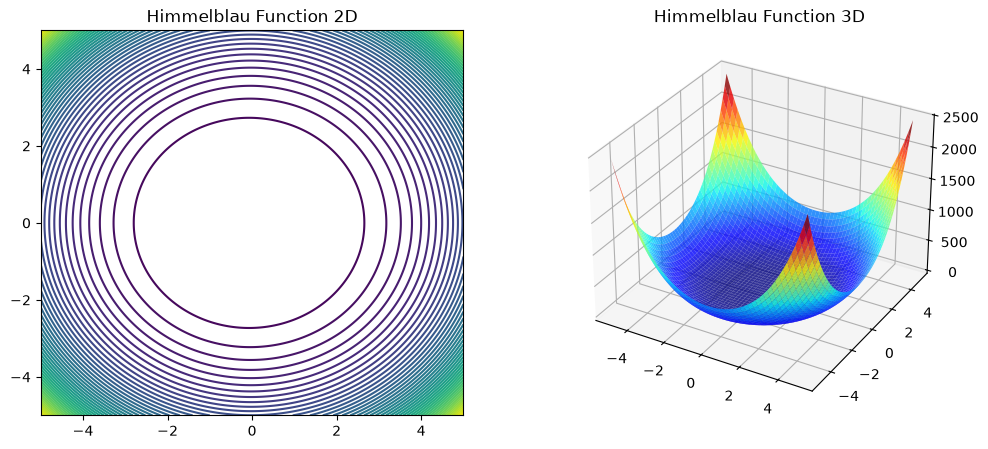

Initial guess [0, 4.7], Result: [-1.00000004e+00 -1.38826348e-07], Value: 2.7507449582319957e-14, Success: True, Iterations: 14
Initial guess [-5.7, 6.5], Result: [-1.00000028e+00 -7.54364510e-08], Value: 3.9191027681006657e-13, Success: True, Iterations: 24
Initial guess [17, 12], Result: [-1.00000040e+00 -4.21052093e-07], Value: 9.596965467481422e-13, Success: True, Iterations: 30
PyGAD initial guess [0, 4.7], Solution: [-1.02151152 -0.00138308], Value: 0.002355838899284965


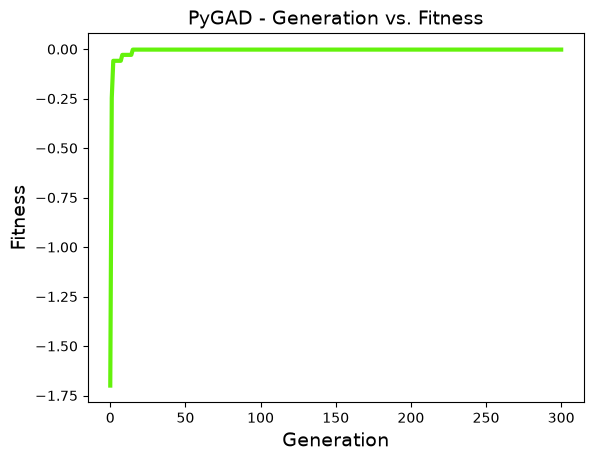

PyGAD initial guess [-5.7, 6.5], Solution: [-0.98959695  0.00611339], Value: 0.0005724532548735014


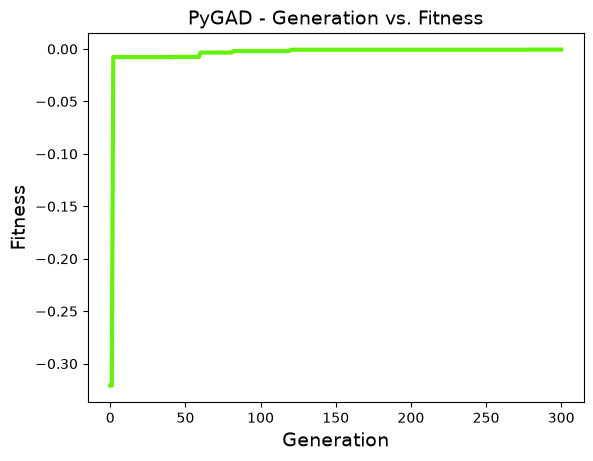

PyGAD initial guess [17, 12], Solution: [-0.98633676 -0.00530518], Value: 0.0009498701043403492


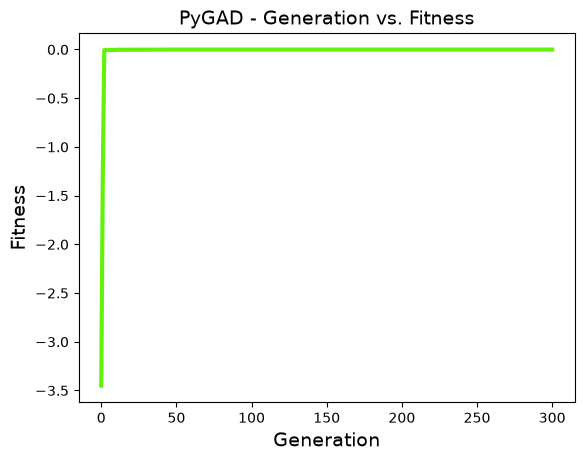

In [19]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1]**2 - 1)**2 + (x[0] + 1)**2 + x[1]**2
    print(x)
# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[0, 4.7], [-5.7, 6.5], [17, 12]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(himmelblau, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}") # TODO include iterations and time taken
    # Uncomment to plot fitness: 
    ga_instance.plot_fitness()